# Frozen reader: full held-out test

The production package was frozen before this single test run. All **325 questions across 24 stories** are included. These cells inspect the actual completed cloud outputs and their independent source/reference replay. They do not train a model or choose a policy from test outcomes.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'docs').exists():
    root = root.parent
result = json.loads((root / 'docs/final-test.json').read_bytes())
metrics = result['metrics']
assert result['complete'] and metrics['n'] == 325 and result['stories'] == 24
for check in ['all_prediction_raw_sha_exact', 'source_reference_metric_replay_exact', 'all_citations_full_source_and_section_bounds_exact', 'cloud_reload325_receipt_bound']:
    assert result[check]
print('Questions:', metrics['n'], 'Stories:', result['stories'])
print('Source families:', result['families'])
print('Test run:', result['kernel'])

Questions: 325 Stories: 24
Source families: ['beatrix-potter-fairybook', 'grimm-fairybook']
Test run: aikyatansinha/portfolio-narrative-sealed-full325-v1/1


## Answer and evidence measurements

Token F1 and exact match compare generated answers with human references. Evidence recall compares retrieved sections with annotated evidence. Citation validity checks exact quoted source offsets, not semantic entailment. The validation and test populations differ; their scores are not an improvement comparison.

f1: 0.456956
em: 0.221538
rouge_l: 0.470014
evidence_recall: 0.964615
citation_validity: 1.000000


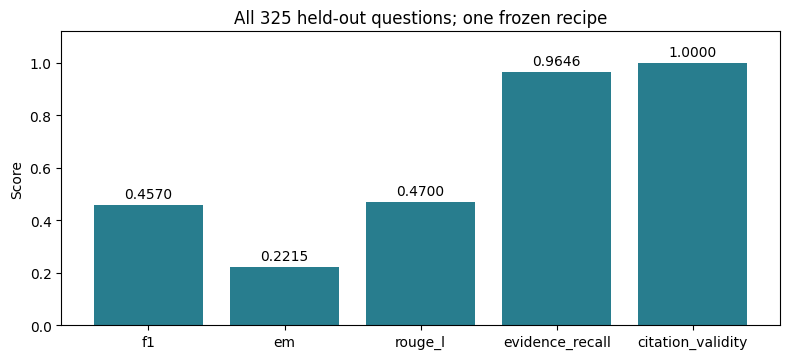

In [2]:
names = ['f1', 'em', 'rouge_l', 'evidence_recall', 'citation_validity']
for name in names:
    print(f'{name}: {metrics[name]:.6f}')
fig, ax = plt.subplots(figsize=(8, 3.7))
bars = ax.bar(names, [metrics[name] for name in names], color='#287d8e')
ax.bar_label(bars, fmt='%.4f', padding=3)
ax.set(ylim=(0, 1.12), ylabel='Score', title='All 325 held-out questions; one frozen recipe')
fig.tight_layout()
(root / 'assets/plots').mkdir(parents=True, exist_ok=True)
fig.savefig(root / 'assets/plots/full-test-results.png', dpi=160, bbox_inches='tight')
plt.show()

## Source-family coverage

Both held-out families are evaluated in full. Group results describe this fixed test release; they are not used to tune retrieval or decoding.

beatrix-potter-fairybook: n=176, F1=0.477616, EM=0.187500
grimm-fairybook: n=149, F1=0.432551, EM=0.261745


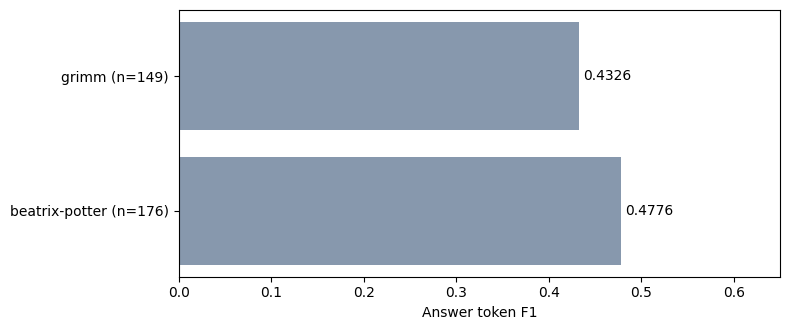

In [3]:
groups = metrics['origin']
assert sum(group['n'] for group in groups.values()) == 325
for name, group in groups.items():
    print(f"{name}: n={group['n']}, F1={group['f1']:.6f}, EM={group['em']:.6f}")
fig, ax = plt.subplots(figsize=(8, 3.4))
labels = [f"{name.replace('-fairybook', '')} (n={groups[name]['n']})" for name in groups]
bars = ax.barh(labels, [group['f1'] for group in groups.values()], color='#8798ad')
ax.bar_label(bars, fmt='%.4f', padding=3); ax.set(xlim=(0, .65), xlabel='Answer token F1')
fig.tight_layout(); plt.show()

## Question types

Implicit questions remain harder than explicit ones in this cohort. Small attribute groups should be read with their counts; two prediction questions are insufficient for a stable estimate. No additional training or test retries follow this analysis.

explicit: n=255, F1=0.518356, EM=0.262745
implicit: n=70, F1=0.233282, EM=0.071429


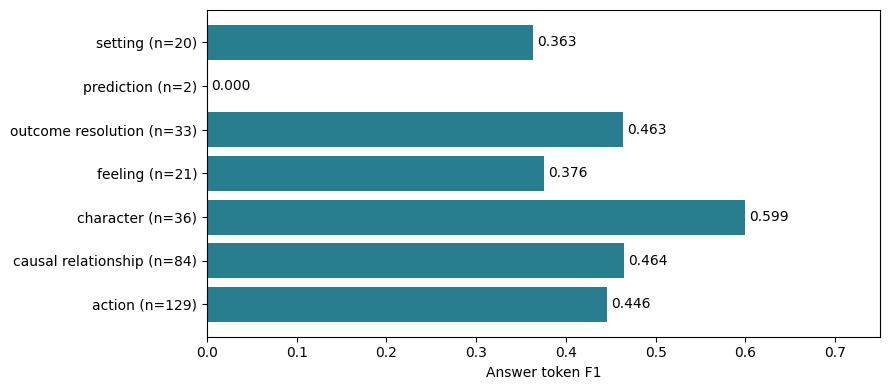

In [4]:
for name, group in metrics['explicit'].items():
    print(f"{name}: n={group['n']}, F1={group['f1']:.6f}, EM={group['em']:.6f}")
attributes = metrics['attribute']
fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{name} (n={group['n']})" for name, group in attributes.items()]
bars = ax.barh(labels, [group['f1'] for group in attributes.values()], color='#287d8e')
ax.bar_label(bars, fmt='%.3f', padding=3); ax.set(xlim=(0, .75), xlabel='Answer token F1')
fig.tight_layout(); plt.show()

## Release and reload checks

The exclusive release marker preceded gold parsing. Every prediction file matched its frozen result hash; an independent replay checked the full cohort, source sections, citations and answer metrics. The cloud job loaded the saved package afresh and reproduced all 325 prediction/citation dictionaries exactly. Host analysis loads JSON and source text, never model weights.

In [5]:
print('Package contract:', result['package_contract_sha256'])
print('Pre-test root freeze:', result['root_freeze_sha256'])
print('Result:', result['result_sha256'])
print('Independent audit:', result['audit_sha256'])
print('All 325 source/reference scores and citation bounds: verified')
print('Fresh package reload: 325/325 exact, as bound by the cloud execution receipt')

Package contract: a3148b684777e34db0c814f27d0f5d24f8437d9f17dbe1c9c466c64f83fd6ff1
Pre-test root freeze: 602fa8b673c63ba2990abe892af130e919f9572701101f41e5cb7f49af29fa2b
Result: 1b1ac1de5ce1928316a4f9c4bdbcf0b0304664b9d2e973ee2a523d0b4d3ce2cc
Independent audit: 5272521964d661cf3748a7ff4e3d9fdb6ee7fddf9bf2d4399326b499e89030f0
All 325 source/reference scores and citation bounds: verified
Fresh package reload: 325/325 exact, as bound by the cloud execution receipt


Story identity is supplied. This custom split is not the official FairytaleQA benchmark, and its 24 stories do not establish adult-novel or cross-book thematic accuracy. Source-valid quotations can accompany unsupported generation. Raw annotations, predictions and model weights stay private; the repository retains aggregate results and reproducible code.